In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

import builtins
builtins.NAMING = "new"


from RealTrace_paper_analysis.plotting_src.header_settings import *
from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *

from matplotlib.lines import Line2D

%config InlineBackend.figure_format ='retina'

header_setting.py: using new naming


In [3]:
def filter_dict(stats, filter_key):
    new_stats = {}
    for pf in stats.keys():
        sample_name = pf.split("/")[-1].split("_")
        if filter_key in sample_name:
            new_stats[pf] = stats[pf]
    return new_stats

In [5]:
indir = "../../data_realtrace_paper/ecoli_data/"
all_files = sorted(find_files(indir, ending="prediction.csv"))


promoters_to_plot = ['hi1', 'hi3', 'rplN', 'rrnB']
conditions_to_plot = conditions[:3]

all_files = [file for file in all_files if file.split("/")[-1].split("_")[0] in conditions_to_plot and file.split("/")[-1].split("_")[1] in promoters_to_plot]    
    
    
all_files = sort_by_condition(all_files)


In [6]:
### Get rate stats ###

def calc_cv(means, covs=None):
    if np.any(covs==None):
        return np.std(means)/np.mean(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)/np.mean(means)

def calc_std(means, covs=None):
    if np.any(covs==None):
        return np.std(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)
    
def calc_mean(means, covs=None):
    if np.any(covs==None):
        mean = np.mean(means)
    else:
        mean = np.sum(means/covs) /np.sum(1/covs)
    return mean

def estimate_rate_stats(filename):
    
    data_prediction = pd.read_csv(filename, skiprows=header_lines(filename))
    cells_prediction = ggp_df2cells(data_prediction)
    stats = {}
    for i in ["l", "q"]:
        zi = "{:s}t".format(i)
        zi_cov = "cov_{:s}{:s}".format(i, i)

        zi_coll_prediction = np.concatenate([cell.__dict__[zi] for cell in cells_prediction])
        zi_coll_prediction_err = np.concatenate([cell.__dict__[zi_cov] for cell in cells_prediction])
        stats["{:s}_mean".format(i)] = calc_mean(zi_coll_prediction, zi_coll_prediction_err)
        stats["{:s}_cv".format(i)] = calc_cv(zi_coll_prediction, zi_coll_prediction_err)
        stats["{:s}_std".format(i)] = calc_std(zi_coll_prediction, zi_coll_prediction_err)

    stats["q_cv/l_cv"]= stats["q_cv"]/ stats["l_cv"]
    ## Adj. units lambda in 1/h, q in 1000/h
    stats['l_mean']*=60
    stats['l_std']*=60
    
    stats['q_mean']*=60/1000
    stats['q_std']*=60/1000

    sample = "_".join(filename.split("/")[-1].split(".")[0].split("_")[:3])
    stats["sample"]= sample
    
    stats["condition"] = filename.split("/")[-1].split("_")[0]
    stats["promoter"] = filename.split("/")[-1].split("_")[1]
    return stats


stats = {}
print("="*len(all_files))
for file in all_files:
    data_set_name = file.split("/")[-1].split("_rawdata")[0]
    print("|", end="")
    stats[data_set_name] = estimate_rate_stats(file)
    

||||||||||||

Saved in ../../figures_for_method_paper/plots_main/correlations/cv_growth.pdf


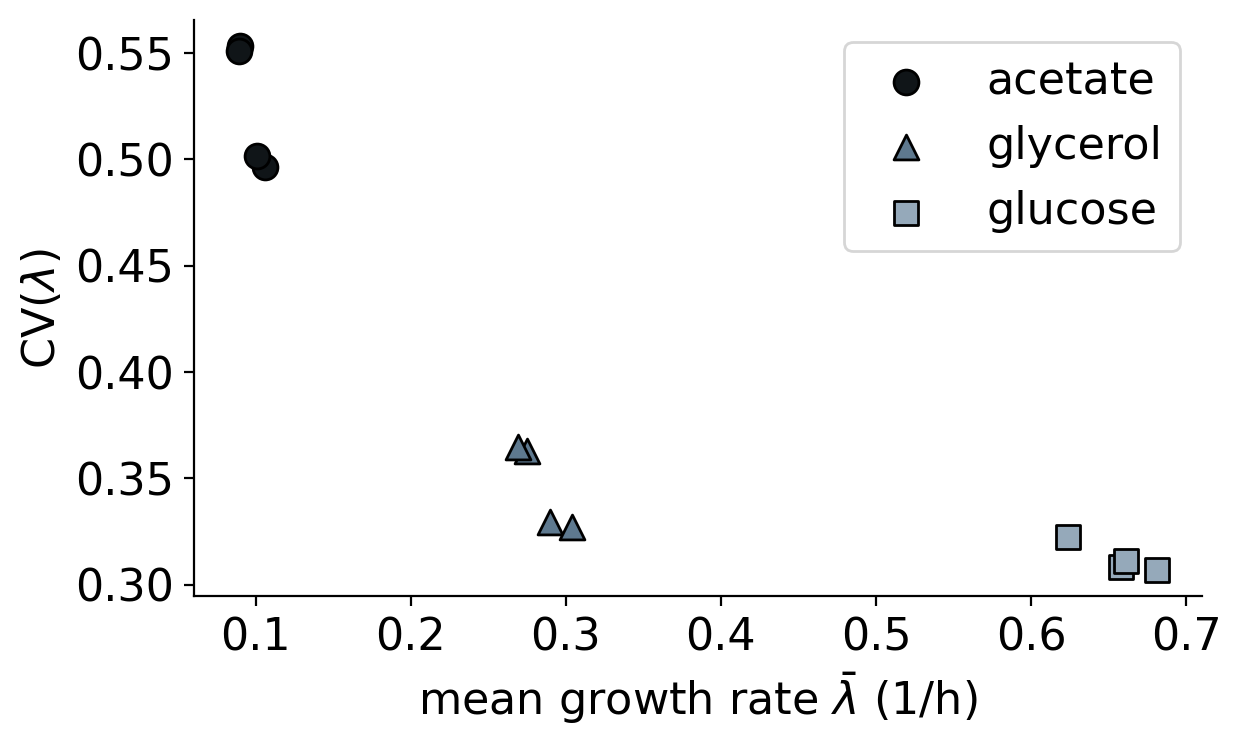

In [7]:

def plot_growth_rate_stats(stats, plot_file=None, color_scheme =None):
    fig, ax = plt.subplots(1,1, figsize=(FULL_SIZE/2,FULL_HEIGHT))
    
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
    
    days = {}
    color_i = 0
    ax.set_xlabel(r"mean growth rate $\bar{\lambda}$ (1/h)")
    ax.set_ylabel(r"CV($\lambda$)")
    for k in stats.keys():
        day = k.split("_")[2]
        condition = get_condition(k)
        promoter = get_promoter(k)
        if color_scheme == "alt":
            altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#5e798f", "#95a9ba", "#d0d9e0" ])}
            color = altcolor_by_condition[condition]
        else:
            color = color_by_promoter[promoter]
            
        ax.scatter(stats[k]["l_mean"], stats[k]["l_cv"], 
                    color=color, 
                    label=label_by_condition[condition], 
                    marker=marker_by_condition[condition],
                    s=80,
                    ec="black")
    ax.yaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=0.05))
    

    ax.legend(*legend_without_duplicate_labels(ax), 
            loc='upper right', 
            bbox_to_anchor=(1, 1), 
            ncol=1)
    
    # ax.tick_params(axis='both', which='minor')

    # ax.minorticks_on()
    # ax.grid(axis="y", which='minor', alpha=0.4)
    # ax.grid(axis="y", which='major')
    
#     legend_elements = [Line2D([0], [0], marker="o", color=color_day[p], ls='none',lw=2, 
#                           label=p) for p in color_day.keys()]
#     legend1 = ax.legend(handles=legend_elements, bbox_to_anchor=(1,0), loc='lower left')
    
#     legend_elements = [Line2D([0], [0], marker=marker_by_condition[p], color="black", ls='none',lw=2, 
#                           label=p) for p in marker_by_condition.keys()]

#     ax.legend(handles=legend_elements, bbox_to_anchor=(1,1), loc='upper left')
#     plt.gca().add_artist(legend1)
    plt.tight_layout()

    if plot_file != None:
        print("Saved in", plot_file)
        fig.savefig(plot_file, dpi=300, facecolor="white", bbox_inches="tight")
        plt.show()

    
    plt.show()
    
plot_growth_rate_stats(stats, plot_file=os.path.join("../../figures_for_method_paper/plots_main/correlations/cv_growth.pdf"), color_scheme="alt")
